# ⚛️ Lab 2: Exploring Quantum Entanglement

### Part A — Foundations: Quantum Circuits and Multi-Qubit Systems

This lab has two parts. **Part A** (below) builds the foundations: multi-qubit circuits, the
tensor product, and the controlled gates (CNOT, CZ, SWAP, Toffoli) that entanglement is built
from. **Part B** puts them to work constructing and exploring entangled qubits — Bell states,
multi-qubit GHZ states, and how correlations scale as systems grow.

By the end of this lab you will be able to:
- Build and read multi-qubit circuits in Qiskit
- Explain how the state space grows as $2^n$ and why that matters
- Compute multi-qubit states using the **tensor (Kronecker) product**
- Use controlled gates (CNOT, CZ, SWAP, Toffoli) and know what each one does
- Explain the difference between superposition and entanglement
- Construct and interpret **Bell states** and larger entangled (GHZ) states
- Avoid the #1 beginner mistake with Qiskit's measurement bit-ordering

$\newcommand{\bra}[1]{\langle#1|}$
$\newcommand{\ket}[1]{|#1\rangle}$

## Setup

In [1]:
# NOTE on a dependency trap (see Lab 1): an old `contourpy` (a matplotlib dependency)
# pins numpy<2.0, while qiskit 2.x requires numpy>=2.0. Installing everything together,
# with numpy/contourpy/matplotlib pinned to mutually-compatible versions, avoids the
# conflict. If you're running this in the same environment as Lab 1, these are likely
# already satisfied.
!pip install -U "numpy>=2.0,<2.8" "contourpy>=1.3" "matplotlib>=3.9" qiskit qiskit-aer pylatexenc charset_normalizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.8 MB/s  0:00:00m 4.8 MB/s eta 0:00:01
  Attempting uninstall: qiskit-aer
    Found existing installation: qiskit-aer 0.18.0
    Uninstalling qiskit-aer-0.18.0:
      Successfully uninstalled qiskit-aer-0.18.0

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram, plot_bloch_multivector, plot_state_qsphere
import numpy as np
import matplotlib.pyplot as plt

simulator = Aer.get_backend('aer_simulator')
statevector_sim = Aer.get_backend('statevector_simulator')

## 1. Review: From Gates to Circuits

### 1.1 Qubit State Representation (recap)

A single qubit's state is $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, with $|\alpha|^2+|\beta|^2=1$,
written as the column vector $\begin{bmatrix}\alpha\\\beta\end{bmatrix}$. Measuring it collapses the
state to $0$ (probability $|\alpha|^2$) or $1$ (probability $|\beta|^2$).

### 1.2 Basic Quantum Gates (recap)

| Gate | Matrix | Effect |
|---|---|---|
| X (NOT) | [[0,1],[1,0]] | Flips \|0⟩ ↔ \|1⟩ |
| Y | [[0,−i],[i,0]] | Bit flip + phase flip |
| Z | [[1,0],[0,−1]] | Flips the sign of \|1⟩ only |
| H (Hadamard) | (1/√2)[[1,1],[1,−1]] | Creates superposition |
| S (Phase) | [[1,0],[0,i]] | 90° phase shift on \|1⟩ |
| T | [[1,0],[0,e^(iπ/4)]] | 45° phase shift on \|1⟩ |

Every gate is a **unitary matrix** — it preserves total probability ($\Sigma|\text{amplitude}|^2=1$
stays true after the gate).

### 1.3 Gate Sequencing

A circuit is a *sequence* of gates. Applying gate $A$ then gate $B$ corresponds to the matrix
product $B \cdot A$ (the first gate applied ends up on the **right** of the product, because it acts
on the state vector first). Order matters — matrices don't generally commute. Let's check this
concretely for $H$ and $X$:

In [3]:
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
X = np.array([[0, 1], [1, 0]])

HX = H @ X   # apply X first, then H
XH = X @ H   # apply H first, then X

print("H @ X =\n", np.round(HX, 3))
print()
print("X @ H =\n", np.round(XH, 3))
print()
print("Are they equal?", np.allclose(HX, XH))

H @ X =
 [[ 0.707  0.707]
 [-0.707  0.707]]

X @ H =
 [[ 0.707 -0.707]
 [ 0.707  0.707]]

Are they equal? False


`H@X` and `X@H` are different matrices — confirming that **gate order changes the result**.
This is why the order you add gates to a circuit matters.

### 1.4 Reading Quantum Circuit Diagrams

- Each horizontal line is a **qubit wire** (or a classical wire, drawn double, after a measurement).
- Time flows **left to right**: the leftmost box on a wire happens first.
- A box with a letter (X, H, T, …) is a single-qubit gate.
- A "meter" symbol (⌐∿⌐) is a **measurement**, which collapses the qubit and writes a classical bit.

Let's build a small circuit and read it both ways — as text and as a diagram:

     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ Z ├┤ H ├┤ X ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


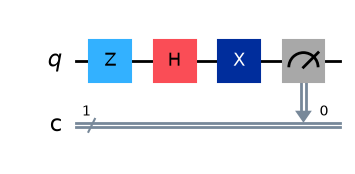

In [4]:
qc = QuantumCircuit(1, 1)
qc.z(0)
qc.h(0)
qc.x(0)
qc.measure(0, 0)

print(qc.draw())
qc.draw('mpl')

**Try It Yourself — Exercise 1.** Build a one-qubit circuit that applies `Z`, then `H`, then `X`
(same order as above, you can copy the circuit), but this time print `qc.depth()` right after
building it (before measuring) and explain in one sentence what that number means. Then add a
measurement and print `qc.depth()` again — did it change, and why?

In [31]:
# Write your solution below
myqc = QuantumCircuit(1,1)
myqc.z(0)
myqc.h(0)
myqc.x(0)
myqc.depth()

3

The number from myqc.depth() is the number of unitary quantum gates cascading each other before measurement.

In [32]:
#Adding a Measure step
myqc.measure(0, 0)
myqc.depth()

4

Adding a .measure() method adds to the depth of the qubit circuit because the measurement is another step affecting the qubit.

Another observation is that in qiskit, running the .measure step multiple times will also add additional depth to the circuit object.

In [33]:
#Adding another Measure step
myqc.measure(0, 0)
myqc.depth()

5

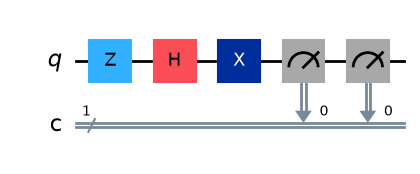

In [36]:
myqc.draw('mpl')

## 2. Quantum Circuits

### 2.1 Quantum Registers

A **quantum register** (`QuantumRegister`) is a named group of qubits. Giving it a name makes
circuit diagrams and multi-register circuits easier to read.

### 2.2 Classical Registers

A **classical register** (`ClassicalRegister`) is where measurement *results* are stored — ordinary
classical bits, not qubits.

### 2.3 Circuit Notation

You can build a `QuantumCircuit` two equivalent ways: from explicit registers, or with the
shorthand `QuantumCircuit(num_qubits, num_clbits)`.

In [6]:
# Explicit registers
qr = QuantumRegister(2, 'q')
cr = ClassicalRegister(2, 'c')
qc_explicit = QuantumCircuit(qr, cr)

# Shorthand (equivalent for our purposes)
qc_shorthand = QuantumCircuit(2, 2)

print("Explicit-register circuit:")
print(qc_explicit.draw())
print("\nShorthand circuit:")
print(qc_shorthand.draw())

Explicit-register circuit:
     
q_0: 
     
q_1: 
     
c: 2/
     

Shorthand circuit:
     
q_0: 
     
q_1: 
     
c: 2/
     


### 2.4 Applying Gates Sequentially

Gates are added with one method call per gate, each naming the qubit(s) it acts on by index
(0, 1, 2, …). Let's build a small multi-qubit circuit:

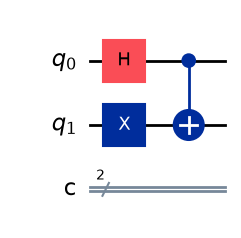

In [7]:
qc = QuantumCircuit(2, 2)
qc.h(0)       # Hadamard on qubit 0
qc.x(1)       # X on qubit 1
qc.cx(0, 1)   # CNOT: control=qubit 0, target=qubit 1
qc.draw('mpl')

### 2.5 Circuit Depth

**Depth** is the number of sequential "layers" the circuit needs — essentially the length of the
longest chain of gates that *must* happen in order. Gates on different qubits that don't depend on
each other can be drawn in the same layer and don't add to the depth. This matters a lot on real
quantum hardware, where every layer accumulates noise.

3 independent H gates -> depth: 1
H + CX(0,1) + CX(1,2) chain -> depth: 3


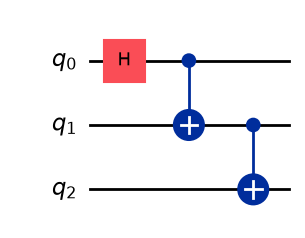

In [8]:
qc_parallel = QuantumCircuit(3)
qc_parallel.h(0)
qc_parallel.h(1)
qc_parallel.h(2)   # all three H's are independent -> 1 layer
print("3 independent H gates -> depth:", qc_parallel.depth())

qc_chain = QuantumCircuit(3)
qc_chain.h(0)
qc_chain.cx(0, 1)
qc_chain.cx(1, 2)  # each CX depends on the previous one -> 3 layers
print("H + CX(0,1) + CX(1,2) chain -> depth:", qc_chain.depth())

qc_chain.draw('mpl')

Three independent `H` gates all happen in parallel (depth 1), but a chain of dependent `CX`
gates can't be compressed — each one needs the previous one's result (depth 3).

### 2.6 Measurement Operations

Two common ways to measure:
- `qc.measure(qubit, clbit)` — measure one specific qubit into one specific classical bit.
- `qc.measure_all()` — measure every qubit, automatically adding a fresh classical register
  named `meas` (even if you already had classical bits).

In [9]:
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure(0, 0)
qc_a.measure(1, 1)
print("Explicit per-qubit measurement:")
print(qc_a.draw())

qc_b = QuantumCircuit(2)
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.measure_all()
print("\nmeasure_all() (adds its own classical register):")
print(qc_b.draw())

Explicit per-qubit measurement:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

measure_all() (adds its own classical register):
        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 


## 3. Multi-Qubit Systems

### 3.1 Single-Qubit vs. Multi-Qubit Systems

One qubit lives in a 2-dimensional space ($\alpha|0\rangle+\beta|1\rangle$). Two qubits don't just
add another 2 dimensions — they live in a $2\times2=4$-dimensional space. In general, $n$ qubits
live in a $2^n$-dimensional space. This exponential growth is both *why quantum computers are
powerful* and *why they're hard to simulate classically* (more on this in 3.4).

### 3.2 Two-Qubit Basis States

With 2 qubits there are four computational basis states, written as 4-dimensional standard basis
vectors:

$$
|00\rangle=\begin{bmatrix}1\\0\\0\\0\end{bmatrix} \quad
|01\rangle=\begin{bmatrix}0\\1\\0\\0\end{bmatrix} \quad
|10\rangle=\begin{bmatrix}0\\0\\1\\0\end{bmatrix} \quad
|11\rangle=\begin{bmatrix}0\\0\\0\\1\end{bmatrix}
$$

> **A heads-up about notation** (we'll cover this fully in Section 8.5): in Qiskit, when you see a
> label like `|01⟩` in a printed statevector or a measurement result, the **rightmost** digit is
> qubit 0 and the **leftmost** digit is the highest-indexed qubit. Keep this in your back pocket.

### 3.3 State-Vector Representation

A general 2-qubit state is a superposition of all four basis states:

$$|\psi\rangle = c_{00}|00\rangle + c_{01}|01\rangle + c_{10}|10\rangle + c_{11}|11\rangle,
\qquad \sum |c_{ij}|^2 = 1$$

**What are the $c$'s?** The four numbers $c_{00}, c_{01}, c_{10}, c_{11}$ are called **probability
amplitudes** — think of each one as telling us *how much* of that basis state is present in
$|\psi\rangle$. For example,

$$|\psi\rangle = \frac{1}{\sqrt2}|00\rangle + \frac{1}{\sqrt2}|11\rangle$$

means only two basis states have an amplitude at all: $c_{00}=c_{11}=1/\sqrt2$, while
$c_{01}=c_{10}=0$. Before measurement, the system is a superposition of exactly `|00⟩` and
`|11⟩` — nothing else.

**Amplitude is not probability.** This is the detail that trips people up. The $c$ values are
amplitudes, *not* probabilities themselves — to get a probability, take the magnitude **squared**:

$$P(00) = |c_{00}|^2, \qquad P(01) = |c_{01}|^2, \qquad P(10)=|c_{10}|^2, \qquad P(11)=|c_{11}|^2$$

For our example, $\left|1/\sqrt2\right|^2 = 1/2$, so:

| State | Probability |
|---|---|
| `\|00⟩` | 50% |
| `\|01⟩` | 0% |
| `\|10⟩` | 0% |
| `\|11⟩` | 50% |

**Why must the probabilities add to 1?** The compact expression $\sum|c_{ij}|^2=1$ is just shorthand
for $|c_{00}|^2+|c_{01}|^2+|c_{10}|^2+|c_{11}|^2=1$ — and that has to hold because *some* measurement
outcome happens 100% of the time. (A split like $25\%+25\%+25\%+25\%=100\%$ would satisfy this just
as well as our $50\%+0\%+0\%+50\%$ example does.)

**Why it's called "state-vector representation."** The same superposition can be written as a plain
column vector, with one entry per basis state:

$$|\psi\rangle = \begin{bmatrix}c_{00}\\c_{01}\\c_{10}\\c_{11}\end{bmatrix}$$

For our running example, $|\psi\rangle = (|00\rangle+|11\rangle)/\sqrt2$ has the state vector

$$\begin{bmatrix}1/\sqrt2\\0\\0\\1/\sqrt2\end{bmatrix}$$

— which, as it happens, is exactly the Bell state $|\Phi^+\rangle$ we'll build properly in Section 7.

**Putting it in one sentence:** a two-qubit system has four possible basis states; the state vector
gives the amplitude of each one; squaring each amplitude's magnitude gives its measurement
probability; and all four probabilities must add up to 1.

One pattern from this is worth memorizing now, since we'll lean on it for the rest of the notebook:

$$\boxed{n\text{ qubits} \;\rightarrow\; 2^n\text{ amplitudes}}$$

| Qubits | Amplitudes |
|---|---|
| 1 | 2 |
| 2 | 4 |
| 3 | 8 |
| 4 | 16 |

($n=1$ is exactly the single-qubit state vector from Lab 1; $n=2$ is the state vector above.
Section 3.4 pushes this pattern much further.)

In [10]:
psi = Statevector([1/np.sqrt(2), 0, 0, 1/np.sqrt(2)])  # c00, c01, c10, c11 -- note this is the
                                                         # SAME state Statevector(qc) would give
                                                         # you after running the H+CX recipe!
print("Amplitudes:  ", np.round(psi.data.real, 4))
print("Probabilities:", psi.probabilities_dict())

Amplitudes:   [0.7071 0.     0.     0.7071]
Probabilities: {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


### 3.4 The $2^n$ State-Space Growth

Let's see just how fast this grows:

 1 qubits -> 2^1 = 2 amplitudes
 2 qubits -> 2^2 = 4 amplitudes
 3 qubits -> 2^3 = 8 amplitudes
 5 qubits -> 2^5 = 32 amplitudes
10 qubits -> 2^10 = 1,024 amplitudes
20 qubits -> 2^20 = 1,048,576 amplitudes


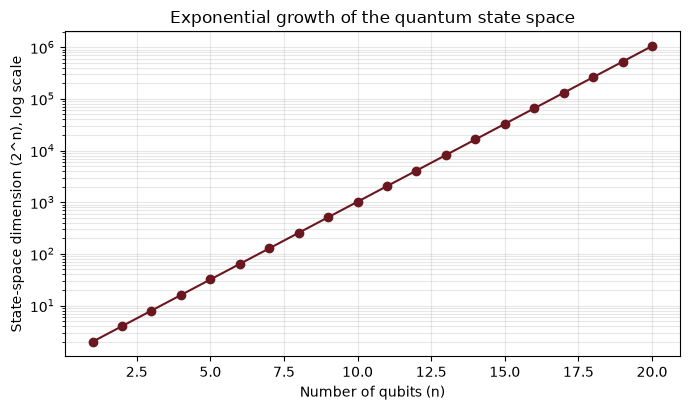

In [11]:
ns = np.arange(1, 21)
dims = 2 ** ns

for n in [1, 2, 3, 5, 10, 20]:
    print(f"{n:>2} qubits -> 2^{n} = {2**n:,} amplitudes")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ns, dims, marker='o', color='#6A171F')
ax.set_yscale('log')
ax.set_xlabel('Number of qubits (n)')
ax.set_ylabel('State-space dimension (2^n), log scale')
ax.set_title('Exponential growth of the quantum state space')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

By 50 qubits, $2^{50}\approx 1.1\times10^{15}$ — over a quadrillion amplitudes. No classical
computer can store a full statevector that large, which is exactly why quantum simulators
(like the one we've been using) only work for modest qubit counts, and why real quantum hardware
matters for anything bigger.

### 3.5 The Tensor (Kronecker) Product

To combine two single-qubit states into one multi-qubit state, we use the **tensor product**
(written $\otimes$, computed in code with `np.kron`). For two 2-dimensional vectors:

$$\begin{bmatrix}a\\b\end{bmatrix}\otimes\begin{bmatrix}c\\d\end{bmatrix}=\begin{bmatrix}ac\\ad\\bc\\bd\end{bmatrix}$$

Let's build $|00\rangle = |0\rangle\otimes|0\rangle$ by hand and check it against Qiskit:

In [12]:
zero = np.array([1, 0])   # |0>

state_00 = np.kron(zero, zero)
print("np.kron(|0>, |0>) =", state_00)

qiskit_00 = Statevector.from_label('00')
print("Statevector.from_label('00') =", qiskit_00.data.real)

print("Match?", np.allclose(state_00, qiskit_00.data.real))

np.kron(|0>, |0>) = [1 0 0 0]
Statevector.from_label('00') = [1. 0. 0. 0.]
Match? True


**Try It Yourself — Exercise 2.** Using `np.kron`, construct the states $|01\rangle$ and
$|10\rangle$ by hand (hint: you'll need `one = np.array([0, 1])` as well as `zero`). Verify each
one against `Statevector.from_label('01')` and `Statevector.from_label('10')`.

In [13]:
# Write your solution below
zero = np.array([1, 0])   # |0>
one = np.array([0, 1])   # |1>

state_00 = np.kron(zero, zero)
print("np.kron(|0>, |0>) =", state_00)

qiskit_00 = Statevector.from_label('00')
print("Statevector.from_label('00') =", qiskit_00.data.real)

print("Match?", np.allclose(state_00, qiskit_00.data.real))



## 4. Operations on Multiple Qubits

### 4.1 Applying a Gate to One Qubit

To apply a single-qubit gate $U$ to just one qubit of a multi-qubit register, we tensor it with the
**identity matrix** $I$ on every other qubit. For 2 qubits, applying $U$ to qubit 0 only while
leaving qubit 1 alone needs a $4\times4$ matrix built from $U$ and $I$ — but in which order? Let's
find out computationally rather than guess.

### 4.2 $H\otimes I$ and $I\otimes H$

Let's build both candidate matrices, then build the *actual* 2-qubit circuit for "H on qubit 0
only" in Qiskit and compare.

In [14]:
I = np.eye(2)

H_tensor_I = np.kron(H, I)   # H on the "left" factor
I_tensor_H = np.kron(I, H)   # H on the "right" factor

print("H ⊗ I =\n", np.round(H_tensor_I, 3))
print()
print("I ⊗ H =\n", np.round(I_tensor_H, 3))

H ⊗ I =
 [[ 0.707  0.     0.707  0.   ]
 [ 0.     0.707  0.     0.707]
 [ 0.707  0.    -0.707 -0.   ]
 [ 0.     0.707 -0.    -0.707]]

I ⊗ H =
 [[ 0.707  0.707  0.     0.   ]
 [ 0.707 -0.707  0.    -0.   ]
 [ 0.     0.     0.707  0.707]
 [ 0.    -0.     0.707 -0.707]]


In [15]:
qc_h0 = QuantumCircuit(2)
qc_h0.h(0)   # H on qubit 0 ONLY

actual_matrix = Operator(qc_h0).data.real
print("Qiskit's actual unitary for 'h(0)' on a 2-qubit circuit:\n", np.round(actual_matrix, 3))

print("\nMatches H ⊗ I ?", np.allclose(actual_matrix, H_tensor_I))
print("Matches I ⊗ H ?", np.allclose(actual_matrix, I_tensor_H))

Qiskit's actual unitary for 'h(0)' on a 2-qubit circuit:
 [[ 0.707  0.707  0.     0.   ]
 [ 0.707 -0.707  0.     0.   ]
 [ 0.     0.     0.707  0.707]
 [ 0.     0.     0.707 -0.707]]

Matches H ⊗ I ? False
Matches I ⊗ H ? True


The result tells us Qiskit's own convention: `qc.h(0)` corresponds to **$I\otimes H$**, not
$H\otimes I$ — qubit 0 is the **right-hand (inner)** factor of the tensor product, and qubit 1 is
the left-hand (outer) factor. In general, for an $n$-qubit register, Qiskit orders tensor products
as $q_{n-1}\otimes\cdots\otimes q_1\otimes q_0$ — the highest-indexed qubit on the left, qubit 0 on
the right. This is the same convention responsible for the bit-ordering quirk we'll see in
Section 8.5 — it's worth internalizing here with concrete matrices rather than just memorizing a
rule.

### 4.3 Parallel Gate Operations

Gates on different qubits with no dependency between them can be applied "at the same time" (same
circuit layer / same depth). Qiskit lets you apply a gate to a list of qubits in one call:

In [16]:
qc_parallel2 = QuantumCircuit(3)
qc_parallel2.h([0, 1, 2])   # H on all three qubits, one call, depth 1
print(qc_parallel2.draw())
print("Depth:", qc_parallel2.depth())

     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     └───┘
Depth: 1


### 4.4 Multi-Qubit State Evolution

A circuit's *overall* unitary is the product of each layer's tensor-product matrix. Let's verify
this for a 2-layer circuit — H on qubit 0 and X on qubit 1 together (layer 1, independent so they
share a layer), then CX (layer 2) — by comparing Qiskit's own `Operator` against a hand-built
matrix product. Section 4.2 established the convention: qubit 1 is the **left** tensor factor,
qubit 0 is the **right** one — so "H on qubit 0, X on qubit 1" combines as $X\otimes H$.

Full circuit:


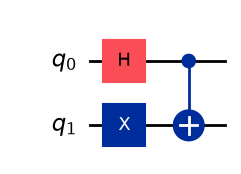

Layer 1 matrix = X ⊗ H:
 [[ 0.     0.     0.707  0.707]
 [ 0.    -0.     0.707 -0.707]
 [ 0.707  0.707  0.     0.   ]
 [ 0.707 -0.707  0.    -0.   ]]

Layer 2 matrix = CNOT:
 [[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]

Manually composed matrix = layer2 @ layer1:
 [[ 0.     0.     0.707  0.707]
 [ 0.707 -0.707  0.     0.   ]
 [ 0.707  0.707  0.     0.   ]
 [ 0.     0.     0.707 -0.707]]

Qiskit's Operator(qc_evolve):
 [[ 0.     0.     0.707  0.707]
 [ 0.707 -0.707  0.     0.   ]
 [ 0.707  0.707  0.     0.   ]
 [ 0.     0.     0.707 -0.707]]

Match? True

Layer 1 circuit:


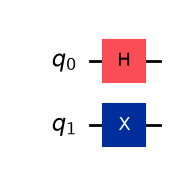

Layer 2 circuit:


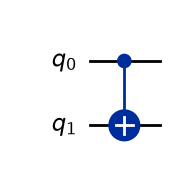

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
from IPython.display import display

# -----------------------------
# 1. Define single-qubit gates
# -----------------------------
H = (1/np.sqrt(2)) * np.array([[1, 1],
                               [1, -1]])

X = np.array([[0, 1],
              [1, 0]])

# -----------------------------
# 2. Build the full circuit
# -----------------------------
qc_evolve = QuantumCircuit(2)
qc_evolve.h(0)
qc_evolve.x(1)
qc_evolve.cx(0, 1)

print("Full circuit:")
display(qc_evolve.draw('mpl'))

# -----------------------------
# 3. Explain the layers
# -----------------------------
# Layer 1:
# H on qubit 0 and X on qubit 1 happen independently,
# so they can be grouped in the same layer.
#
# Qiskit convention here:
# qubit 1 = left tensor factor
# qubit 0 = right tensor factor
#
# Therefore:
# layer1 = X ⊗ H
layer1 = np.kron(X, H)

# Layer 2:
# CNOT only
qc_cx_only = QuantumCircuit(2)
qc_cx_only.cx(0, 1)
layer2 = Operator(qc_cx_only).data.real

# -----------------------------
# 4. Manual total operator
# -----------------------------
# Since layer 2 happens AFTER layer 1:
manual_total = layer2 @ layer1

# Qiskit's total operator
actual_total = Operator(qc_evolve).data.real

# -----------------------------
# 5. Print results
# -----------------------------
print("Layer 1 matrix = X ⊗ H:\n", np.round(layer1, 3))
print("\nLayer 2 matrix = CNOT:\n", np.round(layer2, 3))
print("\nManually composed matrix = layer2 @ layer1:\n", np.round(manual_total, 3))
print("\nQiskit's Operator(qc_evolve):\n", np.round(actual_total, 3))
print("\nMatch?", np.allclose(manual_total, actual_total))

# -----------------------------
# 6. Draw layer circuits
# -----------------------------
qc_layer1 = QuantumCircuit(2)
qc_layer1.h(0)
qc_layer1.x(1)

print("\nLayer 1 circuit:")
display(qc_layer1.draw('mpl'))

print("Layer 2 circuit:")
display(qc_cx_only.draw('mpl'))



## 5. Controlled Quantum Gates

### 5.1 The Concept of Control and Target

A **controlled gate** applies some operation $U$ to a **target** qubit, but *only if* a **control**
qubit is $|1\rangle$. If the control is $|0\rangle$, the target is left untouched. If the control is in
**superposition**, the gate entangles the two qubits — this is the mechanism behind almost every
multi-qubit circuit you'll build.

### 5.2 Controlled-NOT (CNOT / CX)

The most important two-qubit gate. It flips the target qubit if and only if the control is 1.

CNOT matrix (Operator):
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]


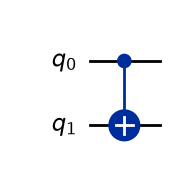

In [18]:
qc_cx = QuantumCircuit(2)
qc_cx.cx(0, 1)   # control=0, target=1
print("CNOT matrix (Operator):")
print(np.round(Operator(qc_cx).data.real, 3))
qc_cx.draw('mpl')

**Truth table, verified by simulation.** Rather than taking the truth table on faith, let's
*generate* it: for each of the 4 computational basis inputs, prepare that input with `X` gates,
apply CX, and read off the resulting statevector. We'll label both input and output the same way
Qiskit labels its own states — $|q_1q_0\rangle$, qubit 1 on the left — so the two columns line up
correctly (mixing label conventions is exactly how truth tables get misread).

In [19]:
print(f"{'input (q1 q0)':>14} -> {'output (q1 q0)':>16}")
for q0_val in [0, 1]:
    for q1_val in [0, 1]:
        qc = QuantumCircuit(2)
        if q0_val: qc.x(0)
        if q1_val: qc.x(1)
        qc.cx(0, 1)   # control=0, target=1
        sv = Statevector(qc)
        output_state = list(sv.to_dict().keys())[0]   # already in Qiskit's q1q0 label order
        input_label = f"{q1_val}{q0_val}"              # match that same q1q0 order
        print(f"         |{input_label}⟩  ->          |{output_state}⟩")

 input (q1 q0) ->   output (q1 q0)
         |00⟩  ->          |00⟩
         |10⟩  ->          |10⟩
         |01⟩  ->          |11⟩
         |11⟩  ->          |01⟩


Reading the $q_1q_0$ labels: $q_0$ (the control, rightmost digit) never changes, and $q_1$
(the target, leftmost digit) only flips on the two rows where $q_0=1$ — exactly the CNOT rule.

**CNOT is the quantum version of XOR.** On classical basis states, CNOT's rule is exactly
`target_new = target ⊕ control` (bitwise XOR). Check it against the truth table above: starting
from `|q1 q0⟩ = |11⟩` (target=1, control=1), XOR gives $1\oplus1=0$, and indeed `|11⟩→|01⟩` — the
target became 0. This is why CNOT is also called **CX** ("controlled-X") *or* "quantum XOR" —
both names describe the same gate.

**CNOT is its own inverse.** Applying it twice does nothing — CNOT is a *reversible* version of
classical XOR-based logic, which is part of why quantum circuits can always be run "backwards":

In [20]:
qc_cx_twice = QuantumCircuit(2)
qc_cx_twice.cx(0, 1)
qc_cx_twice.cx(0, 1)

print("CNOT . CNOT:\n", np.round(Operator(qc_cx_twice).data.real, 3))
print("\nEquals the identity?", np.allclose(Operator(qc_cx_twice).data.real, np.eye(4)))

CNOT . CNOT:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Equals the identity? True


### 5.3 Controlled-Z (CZ)

CZ applies a $Z$ to the target when the control is 1 — but since $Z$ only flips a sign, and that
sign is the *same* whichever qubit you call "control," **CZ is symmetric**: it doesn't matter which
qubit you name as control and which as target.

In [21]:
qc_cz_01 = QuantumCircuit(2)
qc_cz_01.cz(0, 1)
qc_cz_10 = QuantumCircuit(2)
qc_cz_10.cz(1, 0)

print("CZ(0,1) matrix:\n", np.round(Operator(qc_cz_01).data.real, 3))
print("\nCZ(1,0) matrix:\n", np.round(Operator(qc_cz_10).data.real, 3))
print("\nIdentical?", np.allclose(Operator(qc_cz_01).data, Operator(qc_cz_10).data))

CZ(0,1) matrix:
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]

CZ(1,0) matrix:
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]

Identical? True


### 5.4 SWAP Gate

SWAP exchanges the states of two qubits entirely. A fun fact: SWAP can be built from **three CNOT
gates** in a row (alternating control/target) — let's verify that decomposition ourselves.

SWAP matrix:
 [[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]

3-CNOT decomposition matches SWAP? True


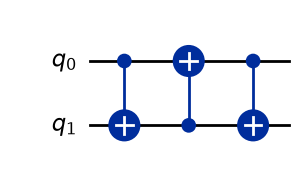

In [22]:
qc_swap = QuantumCircuit(2)
qc_swap.swap(0, 1)

qc_three_cx = QuantumCircuit(2)
qc_three_cx.cx(0, 1)
qc_three_cx.cx(1, 0)
qc_three_cx.cx(0, 1)

print("SWAP matrix:\n", np.round(Operator(qc_swap).data.real, 3))
print("\n3-CNOT decomposition matches SWAP?",
      np.allclose(Operator(qc_swap).data, Operator(qc_three_cx).data))
qc_three_cx.draw('mpl')

Built-in SWAP gate:


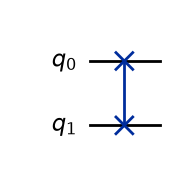

SWAP decomposed into 3 CNOT gates:


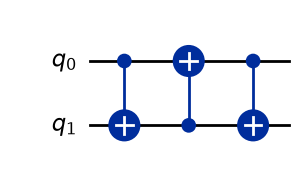


INITIAL STATE
q1 q0 = |01>


MissingOptionalLibraryError: "The 'sympy' library is required to use 'Create a latex representation of a ket expression'. You can install it with 'pip install sympy'."

In [23]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from IPython.display import display

# --------------------------------------------------
# 1. Direct SWAP circuit
# --------------------------------------------------
qc_swap = QuantumCircuit(2)
qc_swap.swap(0, 1)

print("Built-in SWAP gate:")
display(qc_swap.draw('mpl'))


# --------------------------------------------------
# 2. SWAP using three CNOT gates
# --------------------------------------------------
qc_three_cx = QuantumCircuit(2)

qc_three_cx.cx(0, 1)
qc_three_cx.cx(1, 0)
qc_three_cx.cx(0, 1)

print("SWAP decomposed into 3 CNOT gates:")
display(qc_three_cx.draw('mpl'))


# --------------------------------------------------
# 3. Follow one state step by step
# --------------------------------------------------
# Qiskit basis labels are written as |q1 q0>
#
# Start with:
# q1 = 0
# q0 = 1
#
# therefore the initial state is |01>

state = Statevector.from_label('01')

print("\nINITIAL STATE")
print("q1 q0 = |01>")
display(state.draw('latex'))

# --------------------------------------------------
# Step 1: CX(0,1)
# control = q0
# target  = q1
# --------------------------------------------------
step1 = QuantumCircuit(2)
step1.cx(0, 1)

state = state.evolve(step1)

print("\nSTEP 1: CX(0,1)")
print("q0 = 1, so q1 flips")
print("|01>  --->  |11>")
display(step1.draw('mpl'))
display(state.draw('latex'))


# --------------------------------------------------
# Step 2: CX(1,0)
# control = q1
# target  = q0
# --------------------------------------------------
step2 = QuantumCircuit(2)
step2.cx(1, 0)

state = state.evolve(step2)

print("\nSTEP 2: CX(1,0)")
print("q1 = 1, so q0 flips")
print("|11>  --->  |10>")
display(step2.draw('mpl'))
display(state.draw('latex'))


# --------------------------------------------------
# Step 3: CX(0,1)
# control = q0
# target  = q1
# --------------------------------------------------
step3 = QuantumCircuit(2)
step3.cx(0, 1)

state = state.evolve(step3)

print("\nSTEP 3: CX(0,1)")
print("q0 = 0, so nothing changes")
print("|10>  --->  |10>")
display(step3.draw('mpl'))
display(state.draw('latex'))


# --------------------------------------------------
# 4. Final summary
# --------------------------------------------------
print("\nFINAL RESULT:")
print("|01>  --->  |10>")

print("\nThe two qubit values have been swapped.")


# --------------------------------------------------
# 5. Verify that 3 CNOTs = SWAP
# --------------------------------------------------
print("\nSWAP matrix:")
print(np.round(Operator(qc_swap).data.real, 3))

print("\n3-CNOT decomposition matches SWAP?",
      np.allclose(
          Operator(qc_swap).data,
          Operator(qc_three_cx).data
      ))

### 5.5 Toffoli (CCX) Gate

The Toffoli gate (also called CCX, "controlled-controlled-NOT") has **two** control qubits and one
target: the target flips only if *both* controls are 1. It's a 3-qubit gate with an $8\times8$
matrix — and it's important because it's enough, together with H, to build any classical
reversible computation inside a quantum circuit.

In [ ]:
print(f"{'input (q2 q1 q0)':>18} -> {'output (q2 q1 q0)':>20}")
for q0_val in [0, 1]:
    for q1_val in [0, 1]:
        for q2_val in [0, 1]:
            qc = QuantumCircuit(3)
            if q0_val: qc.x(0)
            if q1_val: qc.x(1)
            if q2_val: qc.x(2)
            qc.ccx(0, 1, 2)   # controls = 0,1 ; target = 2
            sv = Statevector(qc)
            output_state = list(sv.to_dict().keys())[0]   # Qiskit's own q2q1q0 label order
            input_label = f"{q2_val}{q1_val}{q0_val}"      # match that same order
            print(f"           |{input_label}⟩  ->            |{output_state}⟩")

Reading the $q_2q_1q_0$ labels: only `011 -> 111` and `111 -> 011` change — that is, exactly
when $q_0=1$ **and** $q_1=1$ (both controls), the target $q_2$ flips (the leftmost digit toggles
between those two rows). Every other row is unchanged, because at least one control is 0.

**Try It Yourself — Exercise 3.** Generate the truth table for the **SWAP** gate yourself, the same
way we generated CNOT's and Toffoli's above (loop over the 4 two-qubit inputs, apply `qc.swap(0,1)`,
print input -> output).

In [ ]:
# Write your solution below




---

# Part B — Building and Exploring Entanglement

With circuits, multi-qubit systems, and controlled gates under your belt, let's put them together
to build **entangled** qubits — states that can't be described qubit-by-qubit, where measuring one
qubit tells you something certain about another.

A quick recap of the two ideas this part is built on:

- **Superposition**: a single qubit can be in a combination of $|0\rangle$ and $|1\rangle$ at once.
- **Entanglement**: two (or more) qubits become linked so that measuring one instantly determines
  what you'll get from the other — even though each one's own result is still random.

## 🔧 Step 1: Build the Bell State Circuit

A Bell state is the simplest example of entanglement — built from exactly the H + CNOT pattern:
Hadamard puts qubit 0 into superposition, then CNOT (Part A, Section 5.1's control/target rule)
links the two qubits together, since its control is no longer definitely 0 or 1.

### Circuit Steps:
1. Apply Hadamard (H) → creates superposition
2. Apply CNOT (CX) → creates entanglement
3. Measure both qubits

### 💬 Before Running

What outcomes do you expect: `00`, `11`, `01`, `10` — some mix of all four, or only some of them?
Write your prediction and reasoning before running the next cell.

*(Write your prediction here.)*

In [ ]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

qc.draw('mpl')

## 🖥️ Step 2: Run on the Simulator

The simulator represents **ideal** quantum behavior: no noise, no hardware limitations.

In [ ]:
compiled_bell = transpile(qc, simulator)
result = simulator.run(compiled_bell, shots=1000).result()
sim_counts = result.get_counts()

print("Simulator result:", sim_counts)

In [ ]:
plot_histogram(sim_counts, title="Bell State — Simulator Result")

### 💬 Reflection Questions

1. Which outputs dominate — did your prediction from Step 1 match?
2. Are `01` and `10` present at all? Why or why not?
3. If you measured *only* qubit 0 and ignored qubit 1 entirely, what would qubit 0's own
   distribution look like? Would that alone prove entanglement?

*(Write your answers here.)*

## 🧪 Part 1 — Advanced Multi-Qubit Entanglement

### 🎯 Objective

Extend the Bell state to **larger entangled systems**, and see how correlations behave as you add
qubits, remove entangling gates, or change the gate that starts things off.

Each task below gives you working starter code — run it first, then answer the questions that
follow using your *actual output*, not a guess.

### 🧩 Task 1 — 3-Qubit GHZ State

The natural 3-qubit generalization of a Bell state is the **GHZ state**,
$(|000\rangle+|111\rangle)/\sqrt2$ — one Hadamard, then a chain of CNOTs linking every qubit to
the first.

In [ ]:
qc_ghz3 = QuantumCircuit(3)
qc_ghz3.h(0)
qc_ghz3.cx(0, 1)
qc_ghz3.cx(1, 2)
qc_ghz3.measure_all()

compiled = transpile(qc_ghz3, simulator)
ghz3_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(ghz3_counts)
plot_histogram(ghz3_counts, title="3-Qubit GHZ State")

**Check:** confirm only `000` and `111` appear (within normal shot noise) — if anything else shows up, something's wrong with the circuit, not with quantum mechanics.

### 🧩 Task 2 — 4-Qubit Entangled System

Extend the same pattern to 4 qubits: one more CNOT, chaining qubit 3 onto qubit 2.

In [ ]:
qc_ghz4 = QuantumCircuit(4)
qc_ghz4.h(0)
qc_ghz4.cx(0, 1)
qc_ghz4.cx(1, 2)
qc_ghz4.cx(2, 3)
qc_ghz4.measure_all()

compiled = transpile(qc_ghz4, simulator)
ghz4_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(ghz4_counts)
plot_histogram(ghz4_counts, title="4-Qubit GHZ State")

**Compare with Task 1:** which two outcomes dominate here, and how does that compare to the
3-qubit case? (Hint: it's the same *pattern*, just one digit longer — tie this back to Part A,
Section 3.4's $2^n$ growth: both states only ever occupy **2** of the $2^n$ available basis
states, no matter how large $n$ gets.)

### 🧩 Task 3 — Partial Entanglement

Take the 4-qubit circuit and remove **one** CNOT — qubit 3 is left completely untouched, so it's
never linked to the rest.

In [ ]:
qc_partial = QuantumCircuit(4)
qc_partial.h(0)
qc_partial.cx(0, 1)
qc_partial.cx(1, 2)
# qc_partial.cx(2, 3)  <- removed: qubit 3 is never entangled with the others
qc_partial.measure_all()

compiled = transpile(qc_partial, simulator)
partial_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(partial_counts)
plot_histogram(partial_counts, title="Partial Entanglement (qubit 3 untouched)")

**Compare with Task 2:** qubit 3 is the leftmost digit in each outcome (Part A, Section 3.2's
bit-ordering convention). What value does it always take, and why — given it starts at $|0\rangle$
and nothing ever acts on it?

### 🧩 Task 4 — Measurement Variation

Go back to the 3-qubit GHZ circuit, but this time measure **only one qubit** instead of all three.
The cell below measures qubit 0 only — **after running it, copy the cell and repeat for qubit 1,
then qubit 2**, changing just the qubit index in `.measure(?, 0)`.

In [ ]:
qc_single = QuantumCircuit(3, 1)
qc_single.h(0)
qc_single.cx(0, 1)
qc_single.cx(1, 2)
qc_single.measure(0, 0)   # <- try changing this 0 to 1, then to 2, in copies of this cell

compiled = transpile(qc_single, simulator)
single_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(single_counts)
plot_histogram(single_counts, title="GHZ, measuring qubit 0 only")

In [ ]:
# Your copy for qubit 1 — measure(1, 0)




In [ ]:
# Your copy for qubit 2 — measure(2, 0)




**Question:** all three single-qubit measurements should come out roughly 50/50. On their
own, does that prove the qubits are entangled? What *would* prove it? (Hint: think about what
happens if you measure two qubits *together*, in the same run, instead of one at a time.)

### 🧩 Task 5 — Controlled Rotation (Advanced)

Replace the Hadamard with a partial rotation, `ry(π/3)`, which creates an *unequal* superposition
instead of a 50/50 one — then chain the same CNOTs as before.

In [ ]:
qc_rotation = QuantumCircuit(3)
qc_rotation.ry(np.pi / 3, 0)
qc_rotation.cx(0, 1)
qc_rotation.cx(1, 2)
qc_rotation.measure_all()

compiled = transpile(qc_rotation, simulator)
rotation_counts = simulator.run(compiled, shots=1000).result().get_counts()
print(rotation_counts)
plot_histogram(rotation_counts, title="GHZ-style state from ry(π/3) instead of H")

**Compare with Task 1:** are `000` and `111` still the *only* two outcomes? Are they still
**equally likely**? If not, why not — think back to Part A, Section 3.3 (amplitudes vs.
probabilities): `ry(π/3)` doesn't split amplitude evenly between $|0\rangle$ and $|1\rangle$ the
way $H$ does, so squaring those unequal amplitudes gives unequal probabilities.

## 🧠 Part 1 Conclusion

Based on Tasks 1–5, answer the following **using your own results**, not copied definitions:

1. How does increasing the number of qubits (Task 1 → Task 2) affect *which* output states can
   appear?
2. What happens to a qubit when it's left out of the entangling chain (Task 3)?
3. Does measuring only one qubit of an entangled system (Task 4) look any different, on its own,
   from measuring a single unentangled qubit in superposition?
4. How did changing the initial gate from $H$ to `ry(π/3)` (Task 5) change the *probabilities*
   without changing *which* outcomes are possible?

Then write a short conclusion (5–10 sentences) summarizing how entanglement changes a system's
behavior, and why multi-qubit entangled systems get harder to reason about as they grow.

*(Write your answers and conclusion here.)*

## 🎯 Conclusion

✔ Entanglement produces perfectly correlated results, not just "spread out" ones
✔ The simulator shows ideal, noise-free quantum behavior
✔ Quantum measurement is inherently probabilistic — individual outcomes are random, but their
  *statistics* are exact and predictable
✔ Entangled states only ever occupy a handful of the $2^n$ available basis states, no matter how
  large the system gets — that's the correlation made visible

### 💬 Final Reflection

> Of everything in Parts A and B, which single demonstration made entanglement feel most
> *concrete* to you — not just a definition, but something you could point to in actual output?
> Explain why in 2–3 sentences.

*(Write your answer here.)*